In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [22]:
df = pd.read_csv(
    "AirQuality.csv",
    sep=";",
    na_values=["-200"]
)

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove empty columns
df = df.loc[:, df.columns != ""]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,"2,6",1360.0,150.0,"11,9",1046.0,166.0,1056.0,113.0,1692.0,1268.0,"13,6","48,9","0,7578",NaN,NaN
1,10/03/2004,19.00.00,2,1292.0,112.0,"9,4",955.0,103.0,1174.0,92.0,1559.0,972.0,"13,3","47,7","0,7255",NaN,NaN
2,10/03/2004,20.00.00,"2,2",1402.0,88.0,"9,0",939.0,131.0,1140.0,114.0,1555.0,1074.0,"11,9","54,0","0,7502",NaN,NaN
3,10/03/2004,21.00.00,"2,2",1376.0,80.0,"9,2",948.0,172.0,1092.0,122.0,1584.0,1203.0,"11,0","60,0","0,7867",NaN,NaN
4,10/03/2004,22.00.00,"1,6",1272.0,51.0,"6,5",836.0,131.0,1205.0,116.0,1490.0,1110.0,"11,2","59,6","0,7888",NaN,NaN


In [23]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Column names:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         7765 non-null   object 
 3   PT08.S1(CO)    8991 non-null   float64
 4   NMHC(GT)       914 non-null    float64
 5   C6H6(GT)       9357 non-null   object 
 6   PT08.S2(NMHC)  8991 non-null   float64
 7   NOx(GT)        7718 non-null   float64
 8   PT08.S3(NOx)   8991 non-null   float64
 9   NO2(GT)        7715 non-null   float64
 10  PT08.S4(NO2)   8991 non-null   float64
 11  PT08.S5(O3)    8991 non-null   float64
 12  T              8991 non-null   object

,PT08.S1(CO),NMHC(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),Unnamed: 15,Unnamed: 16
count,8991.000000,914.000000,8991.000000,7718.000000,8991.000000,7715.000000,8991.000000,8991.000000,0.0,0.0
mean,1099.833166,218.811816,939.153376,246.896735,835.493605,113.091251,1456.264598,1022.906128,NaN,NaN
std,217.080037,204.459921,266.831429,212.979168,256.817320,48.370108,346.206794,398.484288,NaN,NaN
min,647.000000,7.000000,383.000000,2.000000,322.000000,2.000000,551.000000,221.000000,NaN,NaN
25%,937.000000,67.000000,734.500000,98.000000,658.000000,78.000000,1227.000000,731.500000,NaN,NaN
50%,1063.000000,150.000000,909.000000,180.000000,806.000000,109.000000,1463.000000,963.000000,NaN,NaN
75%,1231.000000,297.000000,1116.000000,326.000000,969.500000,142.000000,1674.000000,1273.500000,NaN,NaN
max,2040.000000,1189.000000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,NaN,NaN


In [24]:
# Convert Date and Time into one DateTime column
df["DateTime"] = pd.to_datetime(
    df["Date"].astype(str).str.strip() + " " +
    df["Time"].astype(str).str.strip(),
    format="%d/%m/%Y %H.%M.%S",
    errors="coerce"
)

# Convert pollutant columns to numeric
pollutants = [
    "CO(GT)", "NOx(GT)", "NO2(GT)",
    "C6H6(GT)", "NMHC(GT)"
]

for col in pollutants:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with invalid dates
df = df.dropna(subset=["DateTime"])

# Sort by date and time
df = df.sort_values("DateTime")

print("Data cleaned successfully!")
display(df.head())

Data cleaned successfully!


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16,DateTime
0,10/03/2004,18.00.00,NaN,1360.0,150.0,NaN,1046.0,166.0,1056.0,113.0,1692.0,1268.0,"13,6","48,9","0,7578",NaN,NaN,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2.0,1292.0,112.0,NaN,955.0,103.0,1174.0,92.0,1559.0,972.0,"13,3","47,7","0,7255",NaN,NaN,2004-03-10 19:00:00
2,10/03/2004,20.00.00,NaN,1402.0,88.0,NaN,939.0,131.0,1140.0,114.0,1555.0,1074.0,"11,9","54,0","0,7502",NaN,NaN,2004-03-10 20:00:00
3,10/03/2004,21.00.00,NaN,1376.0,80.0,NaN,948.0,172.0,1092.0,122.0,1584.0,1203.0,"11,0","60,0","0,7867",NaN,NaN,2004-03-10 21:00:00
4,10/03/2004,22.00.00,NaN,1272.0,51.0,NaN,836.0,131.0,1205.0,116.0,1490.0,1110.0,"11,2","59,6","0,7888",NaN,NaN,2004-03-10 22:00:00


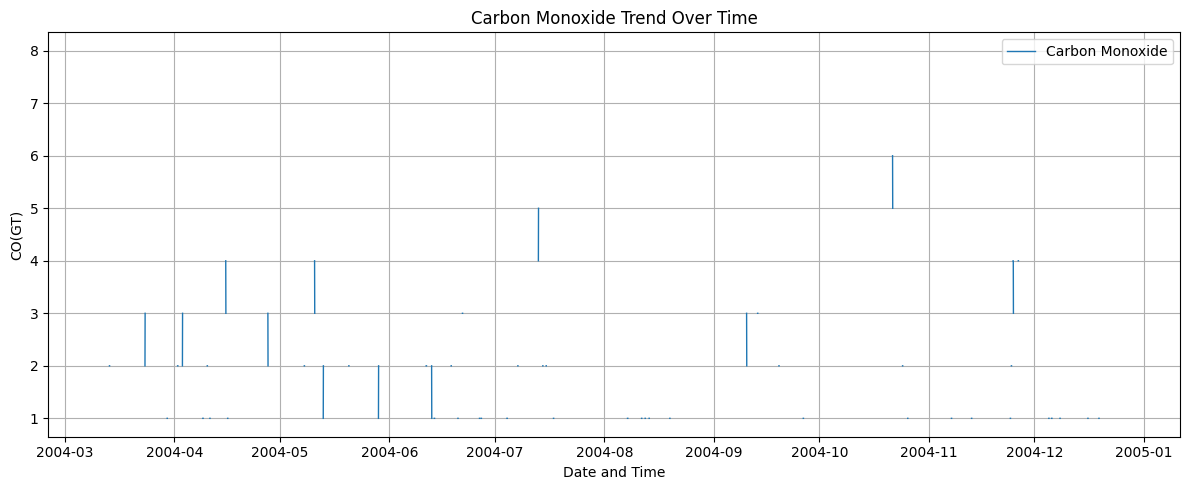

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["DateTime"],
    df["CO(GT)"],
    label="Carbon Monoxide",
    linewidth=1
)

plt.title("Carbon Monoxide Trend Over Time")
plt.xlabel("Date and Time")
plt.ylabel("CO(GT)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

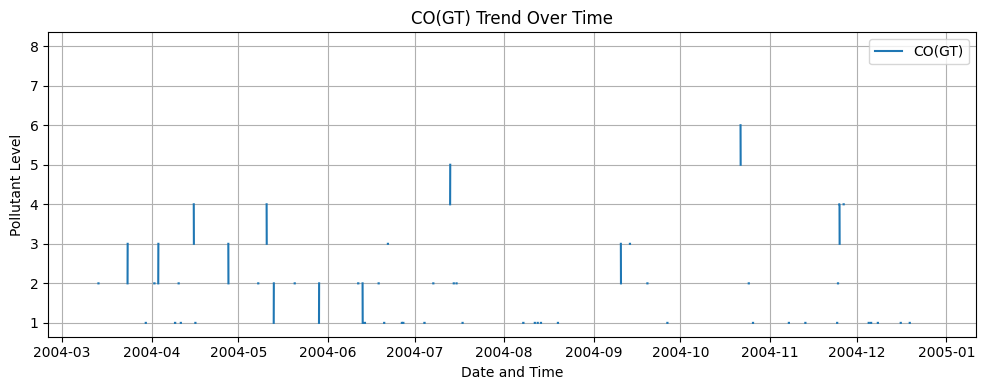

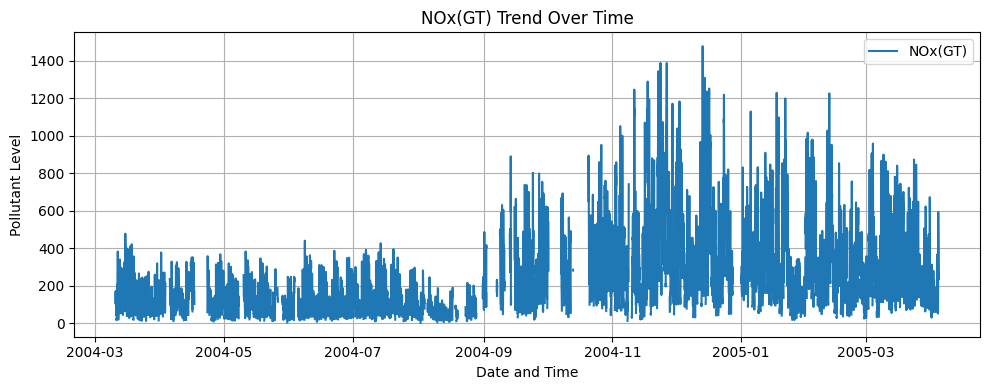

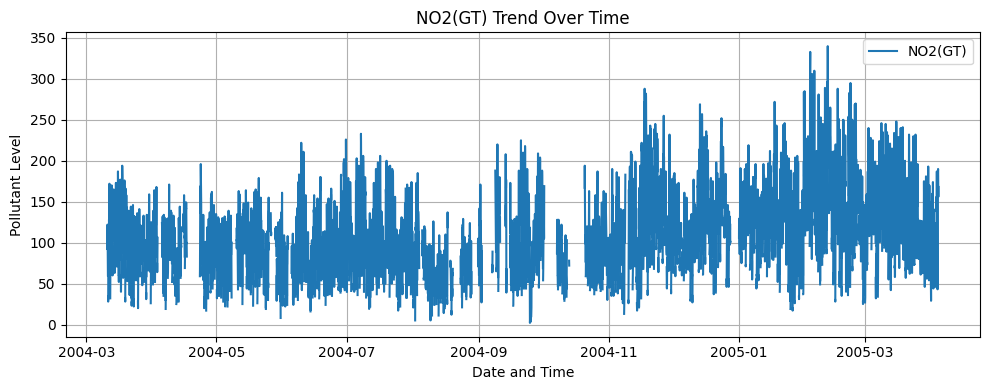

In [26]:
for col in ["CO(GT)", "NOx(GT)", "NO2(GT)"]:
    plt.figure(figsize=(10, 4))

    plt.plot(df["DateTime"], df[col], label=col)

    plt.title(col + " Trend Over Time")
    plt.xlabel("Date and Time")
    plt.ylabel("Pollutant Level")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

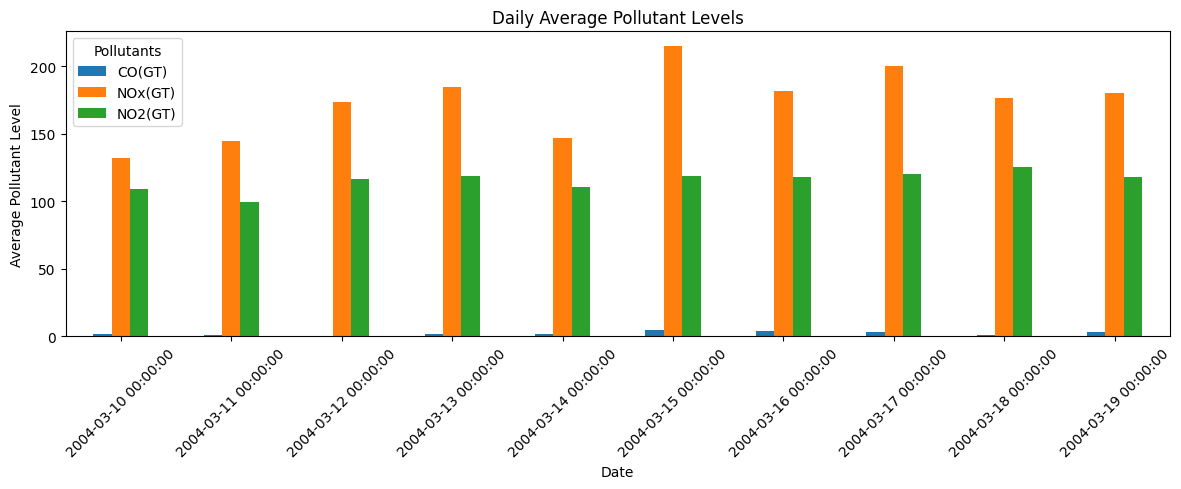

In [27]:
daily_data = df.set_index("DateTime").resample("D")[
    ["CO(GT)", "NOx(GT)", "NO2(GT)"]
].mean()

daily_data = daily_data.dropna(how="all").head(10)

daily_data.plot(kind="bar", figsize=(12, 5))

plt.title("Daily Average Pollutant Levels")
plt.xlabel("Date")
plt.ylabel("Average Pollutant Level")
plt.legend(title="Pollutants")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

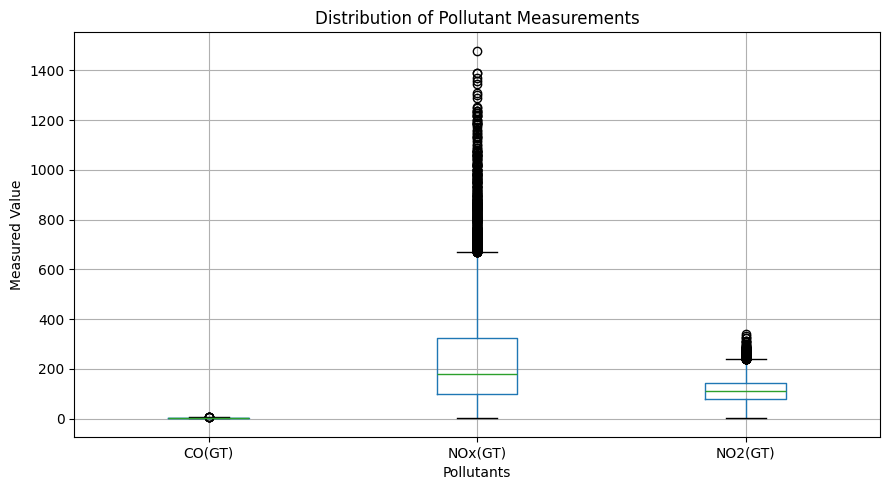

In [28]:
plt.figure(figsize=(9, 5))

df[["CO(GT)", "NOx(GT)", "NO2(GT)"]].boxplot()

plt.title("Distribution of Pollutant Measurements")
plt.xlabel("Pollutants")
plt.ylabel("Measured Value")
plt.grid(True)
plt.tight_layout()
plt.show()

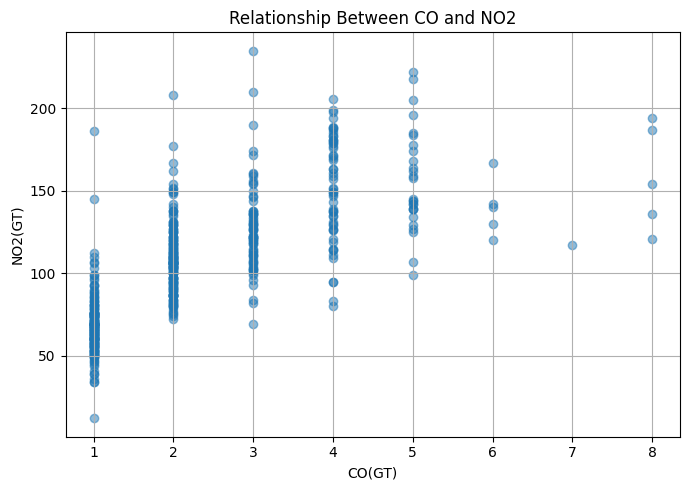

In [29]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df["CO(GT)"],
    df["NO2(GT)"],
    alpha=0.5
)

plt.title("Relationship Between CO and NO2")
plt.xlabel("CO(GT)")
plt.ylabel("NO2(GT)")
plt.grid(True)
plt.tight_layout()
plt.show()

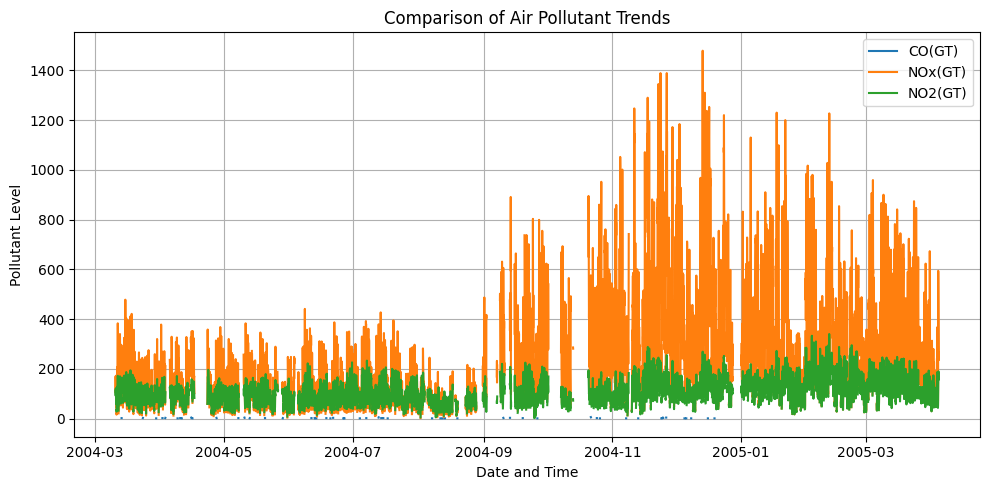

In [30]:
plt.figure(figsize=(10, 5))

for col in ["CO(GT)", "NOx(GT)", "NO2(GT)"]:
    plt.plot(
        df["DateTime"],
        df[col],
        label=col
    )

plt.title("Comparison of Air Pollutant Trends")
plt.xlabel("Date and Time")
plt.ylabel("Pollutant Level")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [31]:
df.to_csv("City_Air_Quality_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
